In [49]:
import matplotlib.pyplot as plt
import numpy as np

from scipy.linalg import lu_factor, lu_solve
from scipy.optimize import curve_fit

np.random.seed(42)

In [50]:
import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

In [51]:
L = 1
Tf = 10
nt = 200000

D = 1

#dx = L/(nx-1)
dt = Tf/nt

wanted_r = 1

dx = np.sqrt(D*dt/wanted_r)
nx = int(L/dx) + 1
dx = L/(nx-1)     

r = D*dt/(dx**2)
h = 0.1

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)


A = np.zeros((nx, nx))
B = np.zeros((nx, nx))

# Nodi interni
for i in range(1, nx-1):
    A[i, i-1] = -r/2
    A[i, i]   = 1 + r
    A[i, i+1] = -r/2

    B[i, i-1] = r/2
    B[i, i]   = 1 - r
    B[i, i+1] = r/2

# Boundary sinistra (Dirichlet)
A[0,0] = 1
#B[0,0] = 1
B[0,:] = 0

# Boundary destra (Robin)
A[-1, -2] = -2*r
A[-1, -1] = 1 + 2*r*(1+h*dx)

B[-1, -2] = 2*r
B[-1, -1] = 1 - 2*r*(1+h*dx)

lu, piv = lu_factor(A)

T = np.zeros(shape=(nx,nt))

# Initial condition
T[:,0] = 0

# Right boundary 
f = np.zeros(nt)
f[0] = 1/dt
T[0,0] = f[0]

for n in range(1,nt):
    b = B @ T[:,n-1]
    b[0] = f[n] # impongo dirichlet
    T[:,n] = lu_solve((lu, piv), b)


Time scale coeff:  1.0
dx:  0.0070921985815602835
dt:  5e-05
r:  0.9940500000000001


<Figure size 340x220 with 0 Axes>

In [52]:
import numpy as np
from scipy.optimize import brentq

def f_eigen(x, h, L):
    return x + h * np.tan(x * L)

def trova_radici(h, L, n_radici):
    radici = []
    k = 0
    while len(radici) < n_radici:
        # Per x + h*tan(xL)=0 con h>0 le radici stanno dove tan < 0,
        # cioè in ( (2k+1)π/(2L) , (k+1)π/L )
        left_asym  = (2*k + 1) * np.pi / (2*L)   # asintoto sinistro
        right_zero = (k + 1)   * np.pi / L        # zero di tan
        
        a = left_asym  + 1e-9
        b = right_zero - 1e-9

        try:
            fa, fb = f_eigen(a, h, L), f_eigen(b, h, L)
            if fa * fb < 0:
                root = brentq(f_eigen, a, b, args=(h, L))
                radici.append(root)
        except Exception:
            pass
        k += 1
    return np.array(radici)

radici = trova_radici(h, L, 3)
radici_squared = radici*radici

print(radici)
print(f"Lambda_0 0 {radici[0]}")

[1.63199453 4.7335118  7.86669277]
Lambda_0 0 1.6319945272148


In [53]:

def func(x, a, q):
    return a*np.exp(-q*x)
    
popt, pcov = curve_fit(func, t_array[30000:], T[nx-1,30000:], p0=(1,(radici[0]*radici[0])/D))
print(popt)

'''
y = T[nx-1, 80000:]
t = t_array[80000:]

logy = np.log(y)

coeff = np.polyfit(t, logy, 1)
q_fit = -coeff[0]

print(q_fit)
'''

print(pcov)

[1.57557604 2.67245961]
[[7.60893173e-30 2.82775074e-30]
 [2.82775074e-30 1.06381745e-30]]


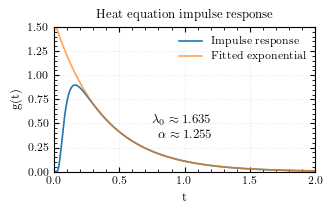

In [54]:
plt.figure(figsize=(3.4, 2.2))

plt.plot(t_array[:], T[nx-1,:], label="Impulse response")
plt.plot(t_array[:], func(t_array[:],*popt), label="Fitted exponential", alpha = 0.7)
plt.text(0.75,0.5, fr"$\lambda_0 \approx {np.sqrt(popt[1]*D):.3f}$")
plt.text(0.8,0.35, fr"$\alpha \approx {np.sqrt(popt[0]):.3f}$")

plt.legend()
plt.ylim([0,1.5])
plt.xlim([0,2])
plt.grid()
plt.title("Heat equation impulse response")

plt.xlabel("t")
plt.ylabel("g(t)")
plt.tight_layout()
plt.minorticks_on()
plt.savefig("assets/funzione_trasferimento_risposta_impulso.pdf")
plt.show()

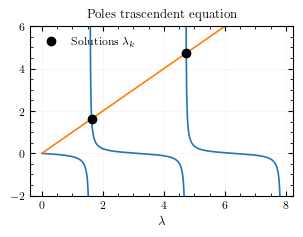

In [55]:
epsilon = 0.001
x_array_plot_1 = np.linspace(0,np.pi/2-epsilon,1000)
x_array_plot_2 = np.linspace(np.pi/2+epsilon,3/2*np.pi-epsilon,1000)
x_array_plot_3 = np.linspace(3*np.pi/2+epsilon,5/2*np.pi-epsilon,1000)

plt.figure(figsize=(3.4, 2.2))   

plt.plot(x_array_plot_1, -h*np.tan(x_array_plot_1*L), color="C0")
plt.plot(x_array_plot_2, -h*np.tan(x_array_plot_2*L), color="C0")
plt.plot(x_array_plot_3, -h*np.tan(x_array_plot_3*L), color="C0")

plt.plot(np.linspace(0,5/2*np.pi-epsilon,1000),np.linspace(0,5/2*np.pi-epsilon,1000), color="C1")

plt.scatter(radici[0], radici[0], c="k", zorder=3, label=r"Solutions $\lambda_k$")
plt.scatter(radici[1], radici[1], c="k", zorder=3)

plt.xlabel(r"$\lambda$")
plt.title("Poles trascendent equation")
plt.grid()
plt.minorticks_on()
plt.legend()
plt.ylim([-2,6])

plt.savefig("assets/trascendent_equation.pdf")